In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!apt-get install sqlite3

In [ ]:
!pip install pandas

In [ ]:
import sqlite3
import pandas as pd
import os #is  for managing your system or else servers

In [ ]:
conn = sqlite3.connect("my_database.db")

In [ ]:
db_path='/content/my_database (2) (1).db'

In [ ]:
db_folder ="/content/drive/MyDrive/sqldb-16"
os.makedirs(db_folder, exist_ok=True)  # Ensure the folder exists
db_path = os.path.join(db_folder, "my_database.db")# joining my folder to my file

In [ ]:
conn = sqlite3.connect(db_path)
cursor =conn.cursor()
print("database at ",db_path)

database at  /content/drive/MyDrive/sqldb-16/my_database.db


In [ ]:
# Ensure db_path and conn are defined. This is a remedial step in case previous cells were not run.
# This assumes the intended database path from cell hNuSFqL7P2SO and connection from IsSLnIsRP2Po.
if 'db_path' not in globals():
    import os
    db_folder ="/content/drive/MyDrive/sqldb-16"
    os.makedirs(db_folder, exist_ok=True)
    db_path = os.path.join(db_folder, "my_database.db")

if 'conn' not in globals():
    import sqlite3
    conn = sqlite3.connect(db_path)

cursor = conn.cursor()
cursor.execute('''
CREATE TABLE BANK_CUSTOM1R ( customer_id INT ,
             	customer_name VARCHAR(20),
             	Address 	VARCHAR(20),
             	state_code  VARCHAR(3) ,
             	Telephone   VARCHAR(10)	);

''')
conn.commit()

In [ ]:
def insert_BANK_CUSTOM1R (customer_id,customer_name,Address,state_code,Telephone):
    cursor.execute("INSERT INTO BANK_CUSTOM1R (customer_id,customer_name,Address,state_code,Telephone) VALUES (?,?, ?, ?,?)", (customer_id,customer_name,Address,state_code,Telephone))
    conn.commit()

# Insertion
insert_BANK_CUSTOM1R(123001,"Oliver", "225-5,Emeryville", "CA" , "1897614500")
insert_BANK_CUSTOM1R(123002,"George", "194-6,New brighton","MN" , "1897617000")

In [ ]:
!pip install tabulate

In [ ]:
from tabulate import tabulate

In [ ]:
#fetch data
cursor.execute('SELECT * FROM BANK_CUSTOM1R')
rows= cursor.fetchall()

#fetching columns names

Column_names = [desc[0] for desc in cursor.description]

#print it as table format
print(tabulate(rows, headers = Column_names, tablefmt="grid"))

+---------------+-----------------+--------------------+--------------+-------------+
|   customer_id | customer_name   | Address            | state_code   |   Telephone |
+===============+=================+====================+==============+=============+
|        123001 | Oliver          | 225-5,Emeryville   | CA           |  1897614500 |
+---------------+-----------------+--------------------+--------------+-------------+
|        123002 | George          | 194-6,New brighton | MN           |  1897617000 |
+---------------+-----------------+--------------------+--------------+-------------+


In [ ]:
#fetch data
cursor.execute('SELECT * FROM BANK_CUSTOM1R')
rows= cursor.fetchall()

#fetching columns names

Column_names = [desc[0] for desc in cursor.description]

#print it as table format
print(tabulate(rows, headers = Column_names, tablefmt="grid"))

All 8 tables created successfully!


3.Insert BANK_CUSTOMER data


In [ ]:
customer_data = [
    (123001, "Oliver", "225-5, Emeryville", "CA", "1897614500"),
    (123002, "George", "194-6,New brighton", "MN", "1897617000"),
    (123003, "Harry", "2909-5,walnut creek", "CA", "1897617866"),
    (123004, "Jack", "229-5, Concord", "CA", "1897627999"),
    (123005, "Jacob", "325-7, Mission Dist", "SFO", "1897637000"),
    (123006, "Noah", "275-9, saint-paul", "MN", "1897613200"),
    (123007, "Charlie", "125-1,Richfield", "MN", "1897617666"),
    (123008, "Robin", "3005-1,Heathrow", "NY", "1897614000")
]

cursor.executemany("""
INSERT INTO BANK_CUSTOMER
(customer_id, customer_name, Address, state_code, Telephone)
VALUES (?, ?, ?, ?, ?)
""", customer_data)

conn.commit()
print("BANK_CUSTOMER loaded:", len(customer_data), "rows")

BANK_CUSTOMER loaded: 8 rows


4. Insert BANK_CUSTOMER_EXPORT data

In [ ]:
customer_export_data = [
    ("123001 ", "Oliver", "225-5, Emeryville", "CA", "1897614500"),
    ("123002 ", "George", "194-6,New brighton", "MN", "189761700")
]

cursor.executemany("""
INSERT INTO BANK_CUSTOMER_EXPORT
(customer_id, customer_name, Address, state_code, Telephone)
VALUES (?, ?, ?, ?, ?)
""", customer_export_data)

conn.commit()
print("BANK_CUSTOMER_EXPORT loaded:", len(customer_export_data), "rows")

BANK_CUSTOMER_EXPORT loaded: 2 rows


5. Insert BANK_ACCOUNT_DETAILS data

In [ ]:
account_details_data = [
    (123001, "4000-1956-3456", "SAVINGS", 200000, "ACTIVE", "P"),
    (123001, "5000-1700-3456", "RECURRING DEPOSITS", 9400000, "ACTIVE", "S"),
    (123002, "4000-1956-2001", "SAVINGS", 400000, "ACTIVE", "P"),
    (123002, "5000-1700-5001", "RECURRING DEPOSITS", 7500000, "ACTIVE", "S"),
    (123003, "4000-1956-2900", "SAVINGS", 750000, "INACTIVE", "P"),
    (123004, "5000-1700-6091", "RECURRING DEPOSITS", 7500000, "ACTIVE", "S"),
    (123004, "4000-1956-3401", "SAVINGS", 655000, "ACTIVE", "P"),
    (123005, "4000-1956-5102", "SAVINGS", 300000, "ACTIVE", "P"),
    (123006, "4000-1956-5698", "SAVINGS", 455000, "ACTIVE", "P"),
    (123007, "5000-1700-9800", "SAVINGS", 355000, "ACTIVE", "P"),
    (123007, "4000-1956-9977", "RECURRING DEPOSITS", 7025000, "ACTIVE", "S"),
    (123007, "9000-1700-7777-4321", "Credit Card", 0, "INACTIVE", "P"),
    (123007, "5900-1900-9877-5543", "Add-on Credit Card", 0, "ACTIVE", "S"),
    (123008, "5000-1700-7755", "SAVINGS", 0, "INACTIVE", "P"),
    (123006, "5800-1700-9800-7755", "Credit Card", 0, "ACTIVE", "P"),
    (123006, "5890-1970-7706-8912", "Add-on Credit Card", 0, "ACTIVE", "S")
]

cursor.executemany("""
INSERT INTO BANK_ACCOUNT_DETAILS
(Customer_id, Account_Number, Account_type, Balance_amount, Account_status, Relationship_type)
VALUES (?, ?, ?, ?, ?, ?)
""", account_details_data)

conn.commit()
print("BANK_ACCOUNT_DETAILS loaded:", len(account_details_data), "rows")

BANK_ACCOUNT_DETAILS loaded: 16 rows


6. Insert BANK_ACCOUNT data


In [ ]:
bank_account_data = [
    (123001, "4000-1956-3456", "SAVINGS", 200000, "ACTIVE", "P"),
    (123001, "5000-1700-3456", "RECURRING DEPOSITS", 9400000, "ACTIVE", "S"),
    (123002, "4000-1956-2001", "SAVINGS", 400000, "ACTIVE", "P"),
    (123002, "5000-1700-5001", "RECURRING DEPOSITS", 7500000, "ACTIVE", "S"),
    (123003, "4000-1956-2900", "SAVINGS", 750000, "INACTIVE", "P"),
    (123004, "5000-1700-6091", "RECURRING DEPOSITS", 7500000, "ACTIVE", "S"),
    (123004, "4000-1956-3401", "SAVINGS", 655000, "ACTIVE", "P"),
    (123005, "4000-1956-5102", "SAVINGS", 300000, "ACTIVE", "P"),
    (123006, "4000-1956-5698", "SAVINGS", 455000, "ACTIVE", "P"),
    (123007, "5000-1700-9800", "SAVINGS", 355000, "ACTIVE", "P"),
    (123007, "4000-1956-9977", "RECURRING DEPOSITS", 7025000, "ACTIVE", "S"),
    (123007, "9000-1700-7777-4321", "CREDITCARD", 0, "INACTIVE", "P"),
    (123008, "5000-1700-7755", "SAVINGS", None, "INACTIVE", "P")
]

cursor.executemany("""
INSERT INTO BANK_ACCOUNT
(Customer_id, Account_Number, Account_type, Balance_amount, Account_status, Relation_ship)
VALUES (?, ?, ?, ?, ?, ?)
""", bank_account_data)

conn.commit()
print("BANK_ACCOUNT loaded:", len(bank_account_data), "rows")

BANK_ACCOUNT loaded: 13 rows


7. Insert BANK_ACCOUNT_RELATIONSHIP_DETAILS data

In [ ]:
relationship_data = [
    (123001, "4000-1956-3456", "SAVINGS", ""),
    (123001, "5000-1700-3456", "RECURRING DEPOSITS", "4000-1956-3456"),
    (123002, "4000-1956-2001", "SAVINGS", ""),
    (123002, "5000-1700-5001", "RECURRING DEPOSITS", "4000-1956-2001"),
    (123003, "4000-1956-2900", "SAVINGS", ""),
    (123004, "5000-1700-6091", "RECURRING DEPOSITS", "4000-1956-2900"),
    (123004, "5000-1700-7791", "RECURRING DEPOSITS", "4000-1956-2900"),
    (123007, "5000-1700-9800", "SAVINGS", ""),
    (123007, "4000-1956-9977", "RECURRING DEPOSITS", "5000-1700-9800"),
    (None, "9000-1700-7777-4321", "Credit Card", "5000-1700-9800"),
    (None, "5900-1900-9877-5543", "Add-on Credit Card", "9000-1700-7777-4321"),
    (None, "5800-1700-9800-7755", "Credit Card", "4000-1956-5698"),
    (None, "5890-1970-7706-8912", "Add-on Credit Card", "5800-1700-9800-7755")
]

cursor.executemany("""
INSERT INTO BANK_ACCOUNT_RELATIONSHIP_DETAILS
(Customer_id, Account_Number, Account_type, Linking_Account_Number)
VALUES (?, ?, ?, ?)
""", relationship_data)

conn.commit()
print("BANK_ACCOUNT_RELATIONSHIP_DETAILS loaded:", len(relationship_data), "rows")

BANK_ACCOUNT_RELATIONSHIP_DETAILS loaded: 13 rows


8. Insert BANK_ACCOUNT_TRANSACTION data

In [ ]:
transaction_data = [
    ("4000-1956-3456", -2000, "ATM withdrawl", "CA", "2020-01-13"),
    ("4000-1956-2001", -4000, "POS-Walmart", "MN", "2020-02-14"),
    ("4000-1956-2001", -1600, "UPI transfer", "MN", "2020-01-19"),
    ("4000-1956-2001", -6000, "Bankers cheque", "CA", "2020-03-23"),
    ("4000-1956-2001", -3000, "Net banking", "CA", "2020-04-24"),
    ("4000-1956-2001", 23000, "cheque deposit", "MN", "2020-03-15"),
    ("5000-1700-6091", 40000, "ECS transfer", "NY", "2020-02-19"),
    ("5000-1700-7791", 40000, "ECS transfer", "NY", "2020-02-19"),
    ("4000-1956-3401", 8000, "Cash Deposit", "NY", "2020-01-19"),
    ("4000-1956-5102", -6500, "ATM withdrawal", "NY", "2020-03-14"),
    ("4000-1956-5698", -9000, "Cash Deposit", "NY", "2020-03-27"),
    ("4000-1956-9977", 50000, "ECS transfer", "NY", "2020-01-16"),
    ("9000-1700-7777-4321", -5000, "POS-Walmart", "NY", "2020-02-17"),
    ("9000-1700-7777-4321", -8000, "Shopping Cart", "MN", "2020-03-13"),
    ("9000-1700-7777-4321", -2500, "Shopping Cart", "MN", "2020-04-21"),
    ("5800-1700-9800-7755", -9000, "POS-Walmart", "MN", "2020-04-13"),
    ("5890-1970-7706-8912", -11000, "Shopping Cart", "NY", "2020-03-12"),
    ("4000-1956-9977", 10000, "ECS transfer", "MN", "2020-02-16"),
    ("4000-1956-9977", 40000, "ECS transfer", "MN", "2020-03-18"),
    ("4000-1956-9977", 60000, "ECS transfer", "MN", "2020-04-18"),
    ("4000-1956-9977", 20000, "ECS transfer", "MN", "2020-03-20"),
    ("4000-1956-9977", 49000, "ECS transfer", "MN", "2020-06-18")
]

cursor.executemany("""
INSERT INTO BANK_ACCOUNT_TRANSACTION
(Account_Number, Transaction_amount, Transcation_channel, Province, Transaction_Date)
VALUES (?, ?, ?, ?, ?)
""", transaction_data)

conn.commit()
print("BANK_ACCOUNT_TRANSACTION loaded:", len(transaction_data), "rows")

BANK_ACCOUNT_TRANSACTION loaded: 22 rows


9. Insert BANK_CUSTOMER_MESSAGES data

In [ ]:
message_data = [
    ("Adhoc", "All Banks are closed due to announcement of National strike", "mobile"),
    ("Transaction Limit", "Only limited withdrawals per card are allowed from ATM machines", "mobile")
]

cursor.executemany("""
INSERT INTO BANK_CUSTOMER_MESSAGES
(Event, Customer_message, Notice_delivery_mode)
VALUES (?, ?, ?)
""", message_data)

conn.commit()
print("BANK_CUSTOMER_MESSAGES loaded:", len(message_data), "rows")

BANK_CUSTOMER_MESSAGES loaded: 2 rows


10.Insert BANK_INTEREST_RATE data

In [ ]:
interest_data = [
    ("SAVINGS", 0.04, "02", "2020"),
    ("RECURRING DEPOSITS", 0.07, "02", "2020"),
    ("PRIVILEGED_INTEREST_RATE", 0.08, "02", "2020")
]

cursor.executemany("""
INSERT INTO BANK_INTEREST_RATE
(account_type, interest_rate, month, year)
VALUES (?, ?, ?, ?)
""", interest_data)

conn.commit()
print("BANK_INTEREST_RATE loaded:", len(interest_data), "rows")

BANK_INTEREST_RATE loaded: 3 rows


11. Verify all tables

In [ ]:
tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""", conn)

display(tables)

print("\nRow counts:")
for table in tables["name"]:
    count = pd.read_sql_query(f"SELECT COUNT(*) AS row_count FROM {table}", conn)
    print(f"{table}: {count.iloc[0,0]} rows")

,name
0,BANK_ACCOUNT
1,BANK_ACCOUNT_DETAILS
2,BANK_ACCOUNT_RELATIONSHIP_DETAILS
3,BANK_ACCOUNT_TRANSACTION
4,BANK_CUSTOM1R
5,BANK_CUSTOMER
6,BANK_CUSTOMER_EXPORT
7,BANK_CUSTOMER_MESSAGES
8,BANK_INTEREST_RATE



Row counts:
BANK_ACCOUNT: 13 rows
BANK_ACCOUNT_DETAILS: 16 rows
BANK_ACCOUNT_RELATIONSHIP_DETAILS: 13 rows
BANK_ACCOUNT_TRANSACTION: 22 rows
BANK_CUSTOM1R: 2 rows
BANK_CUSTOMER: 8 rows
BANK_CUSTOMER_EXPORT: 2 rows
BANK_CUSTOMER_MESSAGES: 2 rows
BANK_INTEREST_RATE: 3 rows


Q1 — Average account balance per customer

**Task:** Print customer ID, customer name, and average account balance maintained by each customer across all accounts.

In [ ]:
query = """
SELECT
    c.customer_id,
    c.customer_name,
    AVG(a.Balance_amount) AS average_account_balance
FROM BANK_CUSTOMER AS c
JOIN BANK_ACCOUNT_DETAILS AS a
    ON c.customer_id = a.Customer_id
GROUP BY
    c.customer_id,
    c.customer_name
ORDER BY c.customer_id;
"""

result = pd.read_sql_query(query, conn)
display(result)

,customer_id,customer_name,average_account_balance
0,123001,Oliver,4.800000e+06
1,123002,George,3.950000e+06
2,123003,Harry,7.500000e+05
3,123004,Jack,4.077500e+06
4,123005,Jacob,3.000000e+05
5,123006,Noah,1.516667e+05
6,123007,Charlie,1.845000e+06
7,123008,Robin,0.000000e+00


Q2 — Credit Card balance using transaction amount when balance is NULL
Task from the document: Print customer ID, account number and balance amount; if balance is nil, use transaction amount for Credit Card accounts.









In [ ]:
query = """
SELECT
    a.Customer_id,
    a.Account_Number,
    COALESCE(a.Balance_amount, t.Transaction_amount) AS balance_amount
FROM BANK_ACCOUNT_DETAILS AS a
LEFT JOIN BANK_ACCOUNT_TRANSACTION AS t
    ON a.Account_Number = t.Account_Number
WHERE a.Account_type = 'Credit Card'
ORDER BY a.Customer_id, a.Account_Number;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Customer_id,Account_Number,balance_amount
0,123006,5800-1700-9800-7755,0
1,123007,9000-1700-7777-4321,0
2,123007,9000-1700-7777-4321,0
3,123007,9000-1700-7777-4321,0


3: Print account_number and balance_amount , transaction_amount,Transaction_Date from Bank_Account_Details and bank_account_transaction for all the transactions occurred during march,2020 and april, 2020(12 Rows)

In [ ]:
query = """
SELECT
    a.Account_Number,
    a.Balance_amount,
    t.Transaction_amount,
    t.Transaction_Date
FROM BANK_ACCOUNT_DETAILS AS a
JOIN BANK_ACCOUNT_TRANSACTION AS t
    ON a.Account_Number = t.Account_Number
WHERE t.Transaction_Date >= '2020-03-01'
  AND t.Transaction_Date < '2020-05-01'
ORDER BY t.Transaction_Date, a.Account_Number;
"""

result = pd.read_sql_query(query, conn)
display(result)
print("Rows returned:", len(result))

,Account_Number,Balance_amount,Transaction_amount,Transaction_Date
0,5890-1970-7706-8912,0,-11000,2020-03-12
1,9000-1700-7777-4321,0,-8000,2020-03-13
2,4000-1956-5102,300000,-6500,2020-03-14
3,4000-1956-2001,400000,23000,2020-03-15
4,4000-1956-9977,7025000,40000,2020-03-18
5,4000-1956-9977,7025000,20000,2020-03-20
6,4000-1956-2001,400000,-6000,2020-03-23
7,4000-1956-5698,455000,-9000,2020-03-27
8,5800-1700-9800-7755,0,-9000,2020-04-13
9,4000-1956-9977,7025000,60000,2020-04-18


Rows returned: 12


4) Print all of the customer id, account number,  balance_amount, transaction_amount , Transaction_Date  from bank_customer, Bank_Account_Details and bank_account_transaction tables where excluding all of their transactions in march, 2020  month (22 Rows)

In [ ]:
query = """
SELECT
    a.Customer_id,
    a.Account_Number,
    a.Balance_amount,
    t.Transaction_amount,
    t.Transaction_Date
FROM BANK_CUSTOMER AS c
JOIN BANK_ACCOUNT_DETAILS AS a
    ON c.customer_id = a.Customer_id
JOIN BANK_ACCOUNT_TRANSACTION AS t
    ON a.Account_Number = t.Account_Number
WHERE t.Transaction_Date < '2020-03-01'
   OR t.Transaction_Date >= '2020-04-01'
ORDER BY a.Customer_id, t.Transaction_Date;
"""

result = pd.read_sql_query(query, conn)
display(result)
print("Rows returned:", len(result))


,Customer_id,Account_Number,Balance_amount,Transaction_amount,Transaction_Date
0,123001,4000-1956-3456,200000,-2000,2020-01-13
1,123002,4000-1956-2001,400000,-1600,2020-01-19
2,123002,4000-1956-2001,400000,-4000,2020-02-14
3,123002,4000-1956-2001,400000,-3000,2020-04-24
4,123004,4000-1956-3401,655000,8000,2020-01-19
5,123004,5000-1700-6091,7500000,40000,2020-02-19
6,123006,5800-1700-9800-7755,0,-9000,2020-04-13
7,123007,4000-1956-9977,7025000,50000,2020-01-16
8,123007,4000-1956-9977,7025000,10000,2020-02-16
9,123007,9000-1700-7777-4321,0,-5000,2020-02-17


Rows returned: 13


5) Print only the customer id, account_number, balance_amount,transaction_amount ,transaction_date who did transactions during the first quarter. Do not display the accounts if they have not done any transactions in the first quarter.(16 Rows)

In [ ]:
query = """
SELECT
    a.Customer_id,
    a.Account_Number,
    a.Balance_amount,
    t.Transaction_amount,
    t.Transaction_Date
FROM BANK_ACCOUNT_DETAILS AS a
JOIN BANK_ACCOUNT_TRANSACTION AS t
    ON a.Account_Number = t.Account_Number
WHERE t.Transaction_Date >= '2020-01-01'
  AND t.Transaction_Date < '2020-04-01'
ORDER BY t.Transaction_Date, a.Customer_id;
"""

result = pd.read_sql_query(query, conn)
display(result)
print("Rows returned:", len(result))

,Customer_id,Account_Number,Balance_amount,Transaction_amount,Transaction_Date
0,123001,4000-1956-3456,200000,-2000,2020-01-13
1,123007,4000-1956-9977,7025000,50000,2020-01-16
2,123002,4000-1956-2001,400000,-1600,2020-01-19
3,123004,4000-1956-3401,655000,8000,2020-01-19
4,123002,4000-1956-2001,400000,-4000,2020-02-14
5,123007,4000-1956-9977,7025000,10000,2020-02-16
6,123007,9000-1700-7777-4321,0,-5000,2020-02-17
7,123004,5000-1700-6091,7500000,40000,2020-02-19
8,123006,5890-1970-7706-8912,0,-11000,2020-03-12
9,123007,9000-1700-7777-4321,0,-8000,2020-03-13


Rows returned: 16


6) Print account_number, Event and Customer_message from BANK_CUSTOMER_MESSAGES and Bank_Account_Details to display an “Adhoc" Event for all customers who have  “SAVINGS" account_type account.(8 Rows)

In [ ]:
query = """
SELECT
    a.Account_Number,
    m.Event,
    m.Customer_message
FROM BANK_ACCOUNT_DETAILS AS a
CROSS JOIN BANK_CUSTOMER_MESSAGES AS m
WHERE a.Account_type = 'SAVINGS'
  AND m.Event = 'Adhoc'
ORDER BY a.Account_Number;
"""

result = pd.read_sql_query(query, conn)
display(result)
print("Rows returned:", len(result))


,Account_Number,Event,Customer_message
0,4000-1956-2001,Adhoc,All Banks are closed due to announcement of Na...
1,4000-1956-2900,Adhoc,All Banks are closed due to announcement of Na...
2,4000-1956-3401,Adhoc,All Banks are closed due to announcement of Na...
3,4000-1956-3456,Adhoc,All Banks are closed due to announcement of Na...
4,4000-1956-5102,Adhoc,All Banks are closed due to announcement of Na...
5,4000-1956-5698,Adhoc,All Banks are closed due to announcement of Na...
6,5000-1700-7755,Adhoc,All Banks are closed due to announcement of Na...
7,5000-1700-9800,Adhoc,All Banks are closed due to announcement of Na...


Rows returned: 8


7) Print all Customer_id, Account_Number, Account_type, and display deducted balance_amount by  subtracting only negative transaction_amounts for Relationship_type ="P" ( P - means  Primary , S - means Secondary ) .(27 Rows)

In [ ]:
query = """
SELECT
    a.Customer_id,
    a.Account_Number,
    a.Account_type,
    a.Balance_amount
      + COALESCE(
          SUM(
              CASE
                  WHEN t.Transaction_amount < 0
                  THEN t.Transaction_amount
                  ELSE 0
              END
          ), 0
        ) AS deducted_balance_amount
FROM BANK_ACCOUNT_DETAILS AS a
LEFT JOIN BANK_ACCOUNT_TRANSACTION AS t
    ON a.Account_Number = t.Account_Number
WHERE a.Relationship_type = 'P'
GROUP BY
    a.Customer_id,
    a.Account_Number,
    a.Account_type,
    a.Balance_amount
ORDER BY a.Customer_id, a.Account_Number;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Customer_id,Account_Number,Account_type,deducted_balance_amount
0,123001,4000-1956-3456,SAVINGS,198000
1,123002,4000-1956-2001,SAVINGS,385400
2,123003,4000-1956-2900,SAVINGS,750000
3,123004,4000-1956-3401,SAVINGS,655000
4,123005,4000-1956-5102,SAVINGS,293500
5,123006,4000-1956-5698,SAVINGS,446000
6,123006,5800-1700-9800-7755,Credit Card,-9000
7,123007,5000-1700-9800,SAVINGS,355000
8,123007,9000-1700-7777-4321,Credit Card,-15500
9,123008,5000-1700-7755,SAVINGS,0


8:- a) Display records of All Accounts , their Account_types, the transaction amount.

b) Along with first step, Display other columns with corresponding linking account number, account types (15 Rows)

In [ ]:
query = """
SELECT
    a.Account_Number,
    a.Account_type,
    t.Transaction_amount,
    r.Linking_Account_Number,
    r.Account_type AS Linking_Account_Type
FROM BANK_ACCOUNT_DETAILS AS a
LEFT JOIN BANK_ACCOUNT_TRANSACTION AS t
    ON a.Account_Number = t.Account_Number
LEFT JOIN BANK_ACCOUNT_RELATIONSHIP_DETAILS AS r
    ON a.Account_Number = r.Account_Number
ORDER BY a.Account_Number, t.Transaction_Date;
"""

result = pd.read_sql_query(query, conn)
display(result)


,Account_Number,Account_type,Transaction_amount,Linking_Account_Number,Linking_Account_Type
0,4000-1956-2001,SAVINGS,-1600.0,,SAVINGS
1,4000-1956-2001,SAVINGS,-4000.0,,SAVINGS
2,4000-1956-2001,SAVINGS,23000.0,,SAVINGS
3,4000-1956-2001,SAVINGS,-6000.0,,SAVINGS
4,4000-1956-2001,SAVINGS,-3000.0,,SAVINGS
5,4000-1956-2900,SAVINGS,NaN,,SAVINGS
6,4000-1956-3401,SAVINGS,8000.0,None,None
7,4000-1956-3456,SAVINGS,-2000.0,,SAVINGS
8,4000-1956-5102,SAVINGS,-6500.0,None,None
9,4000-1956-5698,SAVINGS,-9000.0,None,None


 9: a) Display records of All Accounts , their Account_types, the transaction amount.

b) Along with first step, Display other columns with corresponding linking account number, account types

c)After retrieving all records of accounts and their linked accounts, display the   transaction amount of accounts appeared  in another column.(26 Rows)

In [ ]:
query = """
SELECT
    a.Account_Number,
    a.Account_type,
    t.Transaction_amount,
    r.Linking_Account_Number,
    r.Account_type AS Linking_Account_Type,
    lt.Transaction_amount AS Linked_Account_Transaction_Amount
FROM BANK_ACCOUNT_DETAILS AS a
LEFT JOIN BANK_ACCOUNT_TRANSACTION AS t
    ON a.Account_Number = t.Account_Number
LEFT JOIN BANK_ACCOUNT_RELATIONSHIP_DETAILS AS r
    ON a.Account_Number = r.Account_Number
LEFT JOIN BANK_ACCOUNT_TRANSACTION AS lt
    ON r.Linking_Account_Number = lt.Account_Number
ORDER BY a.Account_Number, t.Transaction_Date, lt.Transaction_Date;
"""

result = pd.read_sql_query(query, conn)
display(result)
print("Rows returned:", len(result))


,Account_Number,Account_type,Transaction_amount,Linking_Account_Number,Linking_Account_Type,Linked_Account_Transaction_Amount
0,4000-1956-2001,SAVINGS,-1600.0,,SAVINGS,NaN
1,4000-1956-2001,SAVINGS,-4000.0,,SAVINGS,NaN
2,4000-1956-2001,SAVINGS,23000.0,,SAVINGS,NaN
3,4000-1956-2001,SAVINGS,-6000.0,,SAVINGS,NaN
4,4000-1956-2001,SAVINGS,-3000.0,,SAVINGS,NaN
5,4000-1956-2900,SAVINGS,NaN,,SAVINGS,NaN
6,4000-1956-3401,SAVINGS,8000.0,None,None,NaN
7,4000-1956-3456,SAVINGS,-2000.0,,SAVINGS,NaN
8,4000-1956-5102,SAVINGS,-6500.0,None,None,NaN
9,4000-1956-5698,SAVINGS,-9000.0,None,None,NaN


Rows returned: 33


10) Display all saving account holders have “Add-on Credit Cards" and “Credit cards"

In [ ]:

query = """
SELECT DISTINCT
    s.Customer_id,
    s.Account_Number AS Savings_Account_Number,
    cc.Account_Number AS Credit_Card_Number,
    cc.Account_type AS Credit_Card_Type,
    addon.Account_Number AS Addon_Card_Number,
    addon.Account_type AS Addon_Card_Type
FROM BANK_ACCOUNT_DETAILS AS s
JOIN BANK_ACCOUNT_RELATIONSHIP_DETAILS AS cc
    ON s.Account_Number = cc.Linking_Account_Number
   AND cc.Account_type = 'Credit Card'
JOIN BANK_ACCOUNT_RELATIONSHIP_DETAILS AS addon
    ON cc.Account_Number = addon.Linking_Account_Number
   AND addon.Account_type = 'Add-on Credit Card'
WHERE s.Account_type = 'SAVINGS'
ORDER BY s.Customer_id;
"""

result = pd.read_sql_query(query, conn)
display(result)


,Customer_id,Savings_Account_Number,Credit_Card_Number,Credit_Card_Type,Addon_Card_Number,Addon_Card_Type
0,123006,4000-1956-5698,5800-1700-9800-7755,Credit Card,5890-1970-7706-8912,Add-on Credit Card
1,123007,5000-1700-9800,9000-1700-7777-4321,Credit Card,5900-1900-9877-5543,Add-on Credit Card


11)  Display  records of “SAVINGS” account linked with “Credit cards" account_type and its credit

-->aggregate sum of transaction amount. (1 Row)

-->Ref: Check linking relationship in bank_transaction_relationship_details.

-->Check transaction_amount in bank_account_transaction.

In [ ]:
query = """
SELECT
    s.Account_Number AS Savings_Account_Number,
    cc.Account_Number AS Credit_Card_Number,
    SUM(t.Transaction_amount) AS Aggregate_Transaction_Amount
FROM BANK_ACCOUNT_RELATIONSHIP_DETAILS AS s
JOIN BANK_ACCOUNT_RELATIONSHIP_DETAILS AS cc
    ON s.Account_Number = cc.Linking_Account_Number
   AND cc.Account_type = 'Credit Card'
JOIN BANK_ACCOUNT_TRANSACTION AS t
    ON cc.Account_Number = t.Account_Number
WHERE s.Account_type = 'SAVINGS'
GROUP BY
    s.Account_Number,
    cc.Account_Number
ORDER BY s.Account_Number;
"""

result = pd.read_sql_query(query, conn)
display(result)


,Savings_Account_Number,Credit_Card_Number,Aggregate_Transaction_Amount
0,5000-1700-9800,9000-1700-7777-4321,-15500


DATA VISUALISTION:-

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
print("Plotting libraries ready.")

Plotting libraries ready.


#Viz 1 — Average account balance per customer

Bar chart version of Q1.

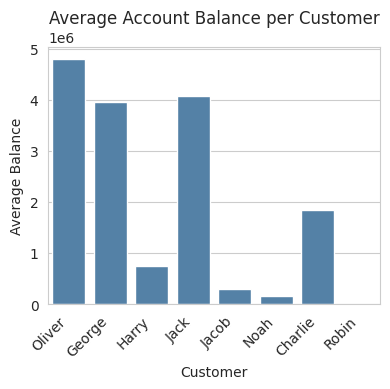

In [ ]:
df1 = pd.read_sql_query("""
SELECT
    c.customer_id,
    c.customer_name,
    AVG(a.Balance_amount) AS average_balance
FROM BANK_CUSTOMER AS c
JOIN BANK_ACCOUNT_DETAILS AS a
    ON c.customer_id = a.Customer_id
GROUP BY c.customer_id, c.customer_name
ORDER BY c.customer_id;
""", conn)

plt.figure(figsize=(4,4))
sns.barplot(data=df1, x="customer_name", y="average_balance", color="steelblue")
plt.title("Average Account Balance per Customer")
plt.xlabel("Customer")
plt.ylabel("Average Balance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Viz 2 — Number of accounts by account type

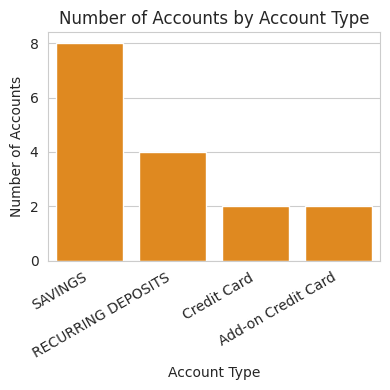

In [ ]:
df2 = pd.read_sql_query("""
SELECT
    Account_type,
    COUNT(*) AS account_count
FROM BANK_ACCOUNT_DETAILS
GROUP BY Account_type
ORDER BY account_count DESC;
""", conn)

plt.figure(figsize=(4,4))
sns.barplot(data=df2, x="Account_type", y="account_count", color="darkorange")
plt.title("Number of Accounts by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Number of Accounts")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Viz 3 — Monthly transaction volume (total amount by month)

Shows the net transaction amount per month across all accounts.

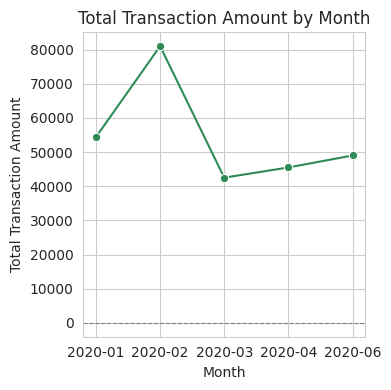

In [ ]:
df3 = pd.read_sql_query("""
SELECT
    strftime('%Y-%m', Transaction_Date) AS month,
    SUM(Transaction_amount) AS total_amount
FROM BANK_ACCOUNT_TRANSACTION
GROUP BY month
ORDER BY month;
""", conn)

plt.figure(figsize=(4,4))
sns.lineplot(data=df3, x="month", y="total_amount", marker="o", color="seagreen")
plt.axhline(0, color="gray", linewidth=0.8, linestyle="--")
plt.title("Total Transaction Amount by Month")
plt.xlabel("Month")
plt.ylabel("Total Transaction Amount")
plt.tight_layout()
plt.show()

Viz 4 — Distribution of transaction amounts

A histogram showing the spread of deposits (positive) vs withdrawals (negative).

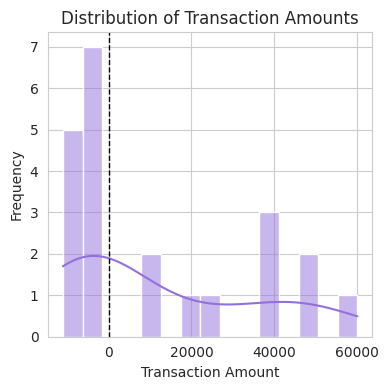

In [ ]:
df4 = pd.read_sql_query("""
SELECT Transaction_amount
FROM BANK_ACCOUNT_TRANSACTION;
""", conn)

plt.figure(figsize=(4,4))
sns.histplot(df4["Transaction_amount"], bins=15, kde=True, color="mediumpurple")
plt.axvline(0, color="black", linewidth=1, linestyle="--")
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Viz 5 — Customers by state

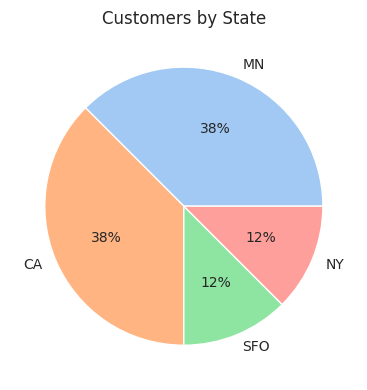

In [ ]:
df5 = pd.read_sql_query("""
SELECT
    state_code,
    COUNT(*) AS customer_count
FROM BANK_CUSTOMER
GROUP BY state_code
ORDER BY customer_count DESC;
""", conn)

plt.figure(figsize=(4,4))
plt.pie(df5["customer_count"], labels=df5["state_code"], autopct="%1.0f%%",
        colors=sns.color_palette("pastel"))
plt.title("Customers by State")
plt.tight_layout()
plt.show()

Viz 6 — Total balance by account status (Active vs Inactive)

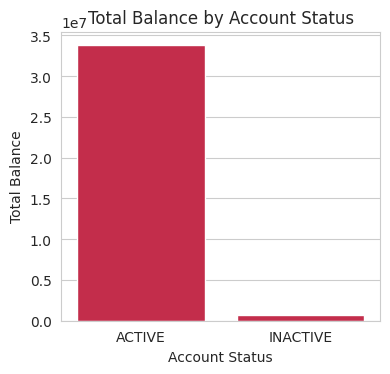

In [ ]:
df6 = pd.read_sql_query("""
SELECT
    Account_status,
    SUM(Balance_amount) AS total_balance
FROM BANK_ACCOUNT_DETAILS
GROUP BY Account_status;
""", conn)

plt.figure(figsize=(4,4))
sns.barplot(data=df6, x="Account_status", y="total_balance", color="crimson")
plt.title("Total Balance by Account Status")
plt.xlabel("Account Status")
plt.ylabel("Total Balance")
plt.tight_layout()
plt.show()